# App-02 : Coloration de graphes (Rust)

[<< App-02 Python](App-02-GraphColoring-Python.ipynb) | [Index de la série](../README.md) | [App-02 C# >>](App-02-GraphColoring-CSharp.ipynb)

***

Ce carnet est le jumeau Rust de [App-02-GraphColoring-Python.ipynb](App-02-GraphColoring-Python.ipynb) : mêmes données, mêmes algorithmes, mêmes questions — mais implémentés en Rust avec la crate **petgraph**. Le fil pédagogique : combien de couleurs faut-il pour colorier une carte (les départements voisins de la petite couronne et au-delà), pourquoi la réponse dépend de l'algorithme choisi, et comment *prouver* le nombre minimal.

**La coloration de graphes est le problème NP-difficile le plus ancien** (le théorème des quatre couleurs, conjecturé en 1852, prouvé en 1976). C'est aussi l'un des plus rentables à bien implémenter : allocation de registres, emploi du temps, fréquences téléphoniques.

## Objectifs d'apprentissage

1. Construire un graphe avec la crate `petgraph` (l'organe de ce carnet) et mesurer sa structure.
2. Implémenter la coloration **gloutonne** (greedy) et mesurer sa **sensibilité à l'ordre** des sommets.
3. Implémenter **DSATUR** (Brélaz, 1979) : choisir dynamiquement le sommet le plus contraint.
4. **Prouver** le nombre chromatique exact par énumération backtracking bornée — le rôle que tient CP-SAT côté Python.
5. Mesurer le compromis qualité / temps de calcul sur des graphes aléatoires G(n, p) à taille croissante.

**Durée estimée** : ~10 min | **Prérequis** : jumeau Python (théorie complète), bases de Rust (ownership, `Vec`, itérateurs) | **Lien** : [Sudoku-02-DancingLinks-Rust.ipynb](../../Sudoku/Sudoku-02-DancingLinks-Rust.ipynb) pour une première prise en main d'evcxr.

## Table des matières

1. [L'organe : la crate petgraph](#1-lorgane-la-crate-petgraph)
2. [Trois algorithmes sur les départements](#2-trois-algorithmes-sur-les-départements)
3. [Benchmark : le compromis qualité / temps](#3-benchmark-le-compromis-qualité--temps)
4. [Exercices](#4-exercices)

## References

- Brélaz, D. (1979). *New Methods to Color the Vertices of a Graph*. Communications of the ACM, 22(4), 251-256.
- Appel, K. & Haken, W. (1976). *Every Planar Map is Four Colorable*. Bulletin of the AMS, 82(5), 711-712.
- Crate [`petgraph`](https://crates.io/crates/petgraph) (MIT/Apache-2.0) — structures de graphes en Rust.
- Crate [`plotters`](https://crates.io/crates/plotters) (MIT) — figures SVG sous evcxr.
- [Carte de l'écosystème Rust du dépôt](../../../docs/reference/rust-ecosystem-map.md) — correspondance bibliothèques Python → crates Rust, série par série.

## 1. L'organe : la crate petgraph

Côté Python, le jumeau s'appuie sur `networkx` pour le graphe et OR-Tools CP-SAT pour la preuve exacte. Côté Rust, l'organe natif est la crate **`petgraph`** (MIT/Apache-2.0) — c'est elle qui porte la structure de graphe, l'itération sur les voisins et les arêtes. Les algorithmes de coloration (greedy, DSATUR) sont, comme côté Python, implémentés à la main : c'est le sujet du carnet.

| Besoin | Jumeau Python | Ce carnet (Rust) |
|---|---|---|
| Structure de graphe, voisins, degrés | `networkx.Graph` | **crate `petgraph`** (`Graph<&str, (), Undirected>`) |
| Planarité | `nx.is_planar(G)` | pas d'équivalent dans petgraph — la planarité géographique est un fait hérité, non mesuré ici |
| Coloration gloutonne, DSATUR | implémentation maison | implémentation maison (même fil) |
| Preuve exacte du nombre chromatique | OR-Tools **CP-SAT** | **backtracking MRV borné maison** (voir § 2.4) |
| Figures | `matplotlib` | crate `plotters` (SVG sous evcxr) |

**Pourquoi pas la crate `cp_sat` ?** La carte d'écosystème du dépôt la recense comme candidat natif partiel, mais elle lie le moteur C++ OR-Tools — qui ne publie aucun binaire pour Windows : il faut une archive Linux sous WSL avec `ORTOOLS_PREFIX`, un prérequis système mesuré hors du périmètre d'un carnet (le détail vit dans [rust-porting-spec.md](../../../docs/reference/rust-porting-spec.md)). Ce jumeau assume donc l'**implémentation brute** : un backtracking exact avec heuristique MRV, qui suffit largement pour des graphes de 18 sommets — et qui a une vertu pédagogique : on voit *comment* une preuve d'optimalité se construit, au lieu de la déléguer.

Un écueil Rust à garder en tête tout du long : **l'aléatoire est un type**. Là où Python appelle `random.shuffle` sur un état global, Rust instancie `StdRng::seed_from_u64(graine)` — chaque tirage est reproductible, graine par graine.

In [2]:
// Dependencies du carnet -- en tete uniquement (un :dep tardif recompile tout
// et efface les variables deja definies). Licences : petgraph MIT/Apache-2.0,
// rand MIT/Apache-2.0, plotters MIT.
:dep petgraph = "0.6"
:dep rand = "0.8"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

## 2. Trois algorithmes sur les départements

### 2.1 Le graphe et sa structure

Le problème jouet du jumeau Python : **18 départements** d'Île-de-France et de la couronne (Paris jusqu'au Nord, l'Aube, l'Yonne...). Chaque département est un sommet ; chaque frontière terrestre commune, une arête. Colorier la carte = assigner une couleur à chaque sommet telle que deux voisins ne partagent jamais la même couleur — un **CSP** (problème de satisfaction de contraintes) :

- **Variables** : un département ;
- **Domaines** : les couleurs disponibles ;
- **Contraintes** : `couleur(u) != couleur(v)` pour chaque arête (u, v).

On construit le graphe avec `petgraph` : les adjacences sont déclarées dans les deux sens (comme le dictionnaire Python), et `Graph::add_edge` créerait une arête parallèle si on ne se protège pas — le dédoublonnage par `contains_edge` reproduit le comportement de `networkx.Graph`. En sortie : les mêmes mesures structurelles que le jumeau (sommets, arêtes, degrés).

In [3]:
// (Les fonctions ne sont pas fiablement persistees d'une cellule a l'autre sous
// evcxr : chaque cellule code est autonome. Les donnees, elles, persistent.)
use petgraph::Graph;
use std::collections::HashMap;

// Adjacences des 18 departements, dans les deux sens (union = 37 frontieres).
let dept_adj_list: Vec<(&str, Vec<&str>)> = vec![
    ("Paris", vec!["Hauts-de-Seine", "Seine-Saint-Denis", "Val-de-Marne"]),
    ("Hauts-de-Seine", vec!["Paris", "Seine-Saint-Denis", "Val-de-Marne", "Yvelines", "Val-d'Oise"]),
    ("Seine-Saint-Denis", vec!["Paris", "Hauts-de-Seine", "Val-de-Marne", "Val-d'Oise", "Seine-et-Marne"]),
    ("Val-de-Marne", vec!["Paris", "Hauts-de-Seine", "Seine-Saint-Denis", "Essonne", "Seine-et-Marne"]),
    ("Essonne", vec!["Val-de-Marne", "Yvelines", "Seine-et-Marne", "Loiret"]),
    ("Yvelines", vec!["Hauts-de-Seine", "Essonne", "Val-d'Oise", "Eure", "Eure-et-Loir"]),
    ("Val-d'Oise", vec!["Hauts-de-Seine", "Seine-Saint-Denis", "Yvelines", "Oise"]),
    ("Seine-et-Marne", vec!["Seine-Saint-Denis", "Val-de-Marne", "Essonne", "Loiret", "Aisne", "Oise", "Marne", "Aube", "Yonne"]),
    ("Oise", vec!["Val-d'Oise", "Seine-et-Marne", "Aisne", "Somme"]),
    ("Aisne", vec!["Oise", "Seine-et-Marne", "Marne", "Somme", "Nord"]),
    ("Loiret", vec!["Essonne", "Seine-et-Marne", "Yonne", "Eure-et-Loir"]),
    ("Eure-et-Loir", vec!["Yvelines", "Loiret", "Eure"]),
    ("Eure", vec!["Yvelines", "Eure-et-Loir", "Oise"]),
    ("Marne", vec!["Seine-et-Marne", "Aisne", "Aube"]),
    ("Aube", vec!["Seine-et-Marne", "Marne", "Yonne"]),
    ("Yonne", vec!["Seine-et-Marne", "Loiret", "Aube"]),
    ("Somme", vec!["Oise", "Aisne", "Nord"]),
    ("Nord", vec!["Aisne", "Somme"]),
];

let mut g: Graph<&str, (), petgraph::Undirected> = Graph::new_undirected();
let mut index: HashMap<&str, petgraph::graph::NodeIndex> = HashMap::new();
for (d, _) in &dept_adj_list {
    let i = g.add_node(d);
    index.insert(d, i);
}
for (d, voisins) in &dept_adj_list {
    for &v in voisins {
        let (a, b) = (index[d], index[v]);
        if !g.contains_edge(a, b) {
            g.add_edge(a, b, ());
        }
    }
}

println!("Graphe des departements");
println!("========================================");
println!("Sommets   : {}", g.node_count());
println!("Aretes    : {}", g.edge_count());
let degres: Vec<usize> = g.node_indices().map(|i| g.neighbors(i).count()).collect();
let dmax = degres.iter().max().copied().unwrap_or(0);
let dmin = degres.iter().min().copied().unwrap_or(0);
let dmoy = degres.iter().sum::<usize>() as f64 / degres.len() as f64;
println!("Degre max : {}   (attendu : 9)", dmax);
println!("Degre min : {}   (attendu : 2)", dmin);
println!("Degre moy : {:.1} (attendu : 4.1)", dmoy);
println!();
println!("Degres par departement (decroissant) :");
let mut tri: Vec<usize> = (0..dept_adj_list.len()).collect();
tri.sort_by(|&a, &b| degres[b].cmp(&degres[a]));
for &i in &tri {
    println!("  {:<20} degre {}", dept_adj_list[i].0, degres[i]);
}

// Adjacence indexee (persistante pour les cellules suivantes).
let n = g.node_count();
let mut adj: Vec<Vec<usize>> = vec![vec![]; n];
for i in g.node_indices() {
    for j in g.neighbors(i) {
        adj[i.index()].push(j.index());
    }
}
let noms: Vec<&str> = (0..n).map(|i| g[petgraph::graph::NodeIndex::new(i)]).collect();
println!();
println!("Adjacence indexee prete : {} sommets, {} aretes au total.", noms.len(), adj.iter().map(|v| v.len()).sum::<usize>() / 2);

Graphe des departements


Sommets   : 18


Aretes    : 37


Degre max : 9   (attendu : 9)


Degre min : 2   (attendu : 2)


Degre moy : 4.1 (attendu : 4.1)


... (16 outputs left out)

  Yonne                degre 3


  Somme                degre 3


  Nord                 degre 2


Adjacence indexee prete : 18 sommets, 37 aretes au total.


### Lecture du résultat

Les mesures retombent **exactement** sur celles du jumeau Python : 18 sommets, 37 arêtes, degré max 9 (**Seine-et-Marne**, la charnière qui touche tout le bassin parisien oriental), degré min 2 (le **Nord**, excentré dans notre échantillon), degré moyen 4,1. C'est la même union des 74 demi-adjacences dédoublonnées en 37 frontières.

Deux lectures utiles pour la suite :

- **La borne gloutonne** : un algorithme glouton ne dépassera jamais Δ + 1 = 10 couleurs sur ce graphe — mais on va voir qu'il s'arrête bien avant.
- **Le théorème des quatre couleurs** garantit que 4 couleurs *suffisent* pour toute carte planaire. La carte est planaire (les frontières se croisent rarement dans le plan), fait que le jumeau Python vérifie avec `networkx.is_planar` et que `petgraph` ne sait pas mesurer — la question devient donc : peut-on descendre sous 4 en pratique, et comment le *prouver* ?

### 2.2 Coloration gloutonne

L'algorithme glouton (**greedy**) est le plus simple qui soit : parcourir les sommets dans un ordre fixé, et donner à chacun la plus petite couleur qu'aucun voisin déjà coloré n'utilise.

```text
pour chaque sommet v (dans l'ordre choisi) :
    pris = couleurs des voisins de v deja colores
    couleur[v] = plus petit entier absent de pris
```

Une seule passe, donc O(V + E). Mais le résultat **dépend entièrement de l'ordre** de parcours : le même graphe peut ressortir à 4 couleurs dans un ordre et à 5 dans un autre. La cellule suivante compare cinq ordres :

1. l'ordre de déclaration (celui du dictionnaire côté jumeau Python) ;
2. deux ordres aléatoires (graines 1 et 2 — l'aléatoire est un type en Rust, la graine se sème explicitement, cf. la carte de l'écosystème) ;
3. l'ordre par **degré décroissant** (heuristique de Welsh-Powell) ;
4. l'ordre par degré croissant — a priori le pire.

Elle échantillonne ensuite 30 ordres aléatoires (graines 0 à 29) pour observer la distribution du nombre de couleurs, puis affiche l'affectation complète obtenue avec l'ordre par défaut.

In [4]:
// Cellule autonome : greedy, validation et ordres redefinis ici.
// (Sous evcxr, un `use` en tete de cellule n'est pas visible depuis le corps
// des fn definies dans la meme cellule : les imports utiles a une fn vivent
// dans son corps.)
fn greedy(adj: &[Vec<usize>], ordre: &[usize]) -> Vec<usize> {
    let n = adj.len();
    let mut couleur = vec![0usize; n];
    let mut colore = vec![false; n];
    for &v in ordre {
        let mut pris = vec![false; n];
        for &u in &adj[v] {
            if colore[u] {
                pris[couleur[u]] = true;
            }
        }
        let mut c = 0;
        while pris[c] {
            c += 1;
        }
        couleur[v] = c;
        colore[v] = true;
    }
    couleur
}

fn nb_couleurs(c: &[usize]) -> usize {
    c.iter().copied().max().map(|m| m + 1).unwrap_or(0)
}

fn valide(adj: &[Vec<usize>], c: &[usize]) -> bool {
    adj.iter().enumerate().all(|(u, vs)| vs.iter().all(|&v| c[u] != c[v]))
}

fn ordre_aleatoire(n: usize, graine: u64) -> Vec<usize> {
    // Melange de Fisher-Yates sur un StdRng seme explicitement :
    // en Rust l'aleatoire est un type, la graine se gere par instance.
    use rand::rngs::StdRng;
    use rand::Rng;
    use rand::SeedableRng;
    let mut rng = StdRng::seed_from_u64(graine);
    let mut o: Vec<usize> = (0..n).collect();
    for i in (1..n).rev() {
        let j = rng.gen_range(0..=i);
        o.swap(i, j);
    }
    o
}

let n = adj.len();
let defaut: Vec<usize> = (0..n).collect();
let mut desc: Vec<usize> = (0..n).collect();
desc.sort_by(|&a, &b| adj[b].len().cmp(&adj[a].len()));
let mut asc: Vec<usize> = (0..n).collect();
asc.sort_by(|&a, &b| adj[a].len().cmp(&adj[b].len()));

println!("Impact de l'ordre sur la coloration greedy");
println!("===========================================");
let cas: Vec<(&str, Vec<usize>)> = vec![
    ("Defaut (declaration)", defaut.clone()),
    ("Aleatoire (graine=1)", ordre_aleatoire(n, 1)),
    ("Aleatoire (graine=2)", ordre_aleatoire(n, 2)),
    ("Degre decroissant", desc.clone()),
    ("Degre croissant", asc.clone()),
];
for (nom, o) in &cas {
    let c = greedy(&adj, o);
    let statut = if valide(&adj, &c) { "OK" } else { "INVALIDE" };
    println!("  {:<24} {:>2} couleurs   [{}]", nom, nb_couleurs(&c), statut);
}

println!();
println!("Echantillon de 30 ordres aleatoires (graines 0..29) :");
let mut tirages: Vec<usize> = (0..30).map(|s| nb_couleurs(&greedy(&adj, &ordre_aleatoire(n, s)))).collect();
tirages.sort();
println!("  min = {}, max = {}", tirages[0], tirages[29]);
for d in tirages[0]..=tirages[29] {
    let freq = tirages.iter().filter(|&&c| c == d).count();
    if freq > 0 {
        println!("  {} couleurs : {:>2} ordres sur 30", d, freq);
    }
}

println!();
let c_def = greedy(&adj, &defaut);
println!("Affectation greedy (ordre par defaut, {} couleurs) :", nb_couleurs(&c_def));
let mut idx: Vec<usize> = (0..n).collect();
idx.sort_by_key(|&i| (c_def[i], i));
for &i in &idx {
    println!("  {:<20} -> couleur {}", noms[i], c_def[i]);
}

Impact de l'ordre sur la coloration greedy


  Defaut (declaration)      4 couleurs   [OK]


  Aleatoire (graine=1)      5 couleurs   [OK]


  Aleatoire (graine=2)      5 couleurs   [OK]


  Degre decroissant         4 couleurs   [OK]


  Degre croissant           5 couleurs   [OK]


... (20 outputs left out)

  Nord                 -> couleur 2


  Val-de-Marne         -> couleur 3


  Yonne                -> couleur 3


()

### Interprétation : la sensibilité à l'ordre

L'ordre par défaut et l'ordre par degré décroissant (Welsh-Powell) colorient la carte en **4 couleurs** ; l'ordre par degré croissant la dégrade (5 couleurs). Les deux ordres aléatoires affichés (graines 1 et 2) tombent eux aussi sur 5. L'échantillon de 30 ordres aléatoires confirme le partage : **16 ordres sur 30** aboutissent à 4 couleurs, **14 sur 30** à 5 — min 4, max 5, **sans jamais garantir lequel** avant d'exécuter. Le jumeau Python observe exactement le même tableau (4 en défaut et degré décroissant, 5 en degré croissant et sur ses graines 1 et 2) : les instances sont les mêmes, seul le générateur aléatoire diffère.

Pourquoi ? Le glouton colorie dans l'ordre de venue : un sommet à fort degré rencontré **tard** a déjà des voisins de couleurs toutes différentes — il en déclenche une nouvelle. Welsh-Powell anticipe en plaçant d'abord les sommets les plus contraints (Seine-et-Marne, degré 9), qui choisissent librement, puis les petits degrés se plient dans les interstices.

La conclusion pédagogique du jumeau Python tient mot pour mot ici : **greedy est rapide, mais son résultat n'est ni optimal ni reproductible** — une même carte, deux ordres, deux budgets. Il faut soit une heuristique plus fine (DSATUR, § 2.3), soit une preuve d'optimalité (§ 2.4).

### 2.3 DSATUR : choisir dynamiquement le plus contraint

DSATUR (Brélaz, 1979) corrige le défaut du greedy : au lieu d'un ordre figé, il **choisit à chaque étape** le sommet non colorié le plus contraint. La *saturation* d'un sommet v est le nombre de **couleurs différentes** déjà présentes dans son voisinage :

$$sat(v) = |\{\, couleur(u) : u \in N(v),\ u\ \text{colorié}\,\}|$$

À chaque étape : prendre le sommet non colorié de **saturation maximale**, départager par **degré maximal** (puis par indice, pour un départage déterministe), et lui donner sa plus petite couleur disponible. L'intuition : plus un sommet est saturé, plus sa fenêtre de choix se referme — c'est lui qu'il faut traiter maintenant.

| | Greedy (ordre fixe) | DSATUR |
|---|---|---|
| Ordre | décidé avant d'exécuter | **dynamique**, recomputé à chaque étape |
| Critère | aucun / degré | saturation, puis degré |
| Complexité | O(V + E) | O(V²) (recherche du max à chaque étape) |
| Résultat | dépend de l'ordre | déterministe, indépendant d'un ordre initial |

La cellule affiche aussi la **trace** pas à pas (étape, sommet choisi, saturation, degré, couleur reçue) — c'est en la lisant qu'on comprend *pourquoi* DSATUR tient 4 couleurs sur ce graphe.

In [5]:
// Cellule autonome : DSATUR avec trace, redefini ici.
fn dsatur(adj: &[Vec<usize>], noms: &[&str], trace: bool) -> Vec<usize> {
    // Import local : les `use` de tete de cellule ne portent pas dans les fn (evcxr).
    use std::collections::HashSet;
    let n = adj.len();
    let non_colore = usize::MAX;
    let mut couleur = vec![non_colore; n];
    // Un HashSet par sommet : les couleurs deja vues dans son voisinage.
    // sat[v] ne change pas quand v est colore -- seulement quand un voisin l'est.
    let mut sat: Vec<HashSet<usize>> = (0..n).map(|_| HashSet::new()).collect();
    if trace {
        println!("Etape  Sommet                Sat  Degre  Couleur");
        println!("-------------------------------------------------");
    }
    for etape in 1..=n {
        // Sommet non colore de saturation max, departage par degre max,
        // puis par indice croissant (departage deterministe).
        let mut meilleur: Option<usize> = None;
        for v in 0..n {
            if couleur[v] != non_colore {
                continue;
            }
            meilleur = match meilleur {
                None => Some(v),
                Some(b) => {
                    let cle_v = (sat[v].len(), adj[v].len());
                    let cle_b = (sat[b].len(), adj[b].len());
                    if cle_v > cle_b { Some(v) } else { Some(b) }
                }
            };
        }
        let Some(v) = meilleur else { break; };
        // Plus petite couleur absente du voisinage deja colore.
        let mut pris: Vec<bool> = vec![false; n];
        for &u in &adj[v] {
            if couleur[u] != non_colore {
                pris[couleur[u]] = true;
            }
        }
        let mut c = 0;
        while pris[c] {
            c += 1;
        }
        let saturation_avant = sat[v].len();
        couleur[v] = c;
        for &u in &adj[v] {
            sat[u].insert(c);
        }
        if trace {
            println!("{:>5}  {:<20} {:>3}  {:>5}  {:>7}", etape, noms[v], saturation_avant, adj[v].len(), c);
        }
    }
    couleur
}

let couleurs = dsatur(&adj, &noms, true);
let nb = 1 + couleurs.iter().copied().max().unwrap_or(0);
let propre = adj.iter().enumerate().all(|(u, vs)| vs.iter().all(|&v| couleurs[u] != couleurs[v]));
println!("-------------------------------------------------");
println!("DSATUR : {} couleurs   [{}]", nb, if propre { "coloration valide" } else { "INVALIDE" });
println!();
println!("Affectation DSATUR (par couleur) :");
let mut idx: Vec<usize> = (0..adj.len()).collect();
idx.sort_by_key(|&i| (couleurs[i], i));
for &i in &idx {
    println!("  {:<20} -> couleur {}", noms[i], couleurs[i]);
}

Etape  Sommet                Sat  Degre  Couleur


-------------------------------------------------


    1  Seine-et-Marne         0      9        0


    2  Seine-Saint-Denis      1      5        1


    3  Val-de-Marne           2      5        2


    4  Hauts-de-Seine         2      5        0


... (32 outputs left out)

  Aube                 -> couleur 2


  Paris                -> couleur 3


  Val-d'Oise           -> couleur 3


()

### Interprétation : la trace

La trace se lit comme un récit de décision. La première étape part d'une saturation nulle partout : c'est le départage par **degré** qui désigne **Seine-et-Marne** (degré 9) — exactement le sommet que Welsh-Powell plaçait en tête, mais ici la décision est *locale* à chaque étape, pas figée d'avance. Ensuite la saturation monte au fil des colorations : les sommets de la petite couronne, pris en tenaille entre Paris et leurs voisins, atteignent des saturations de 2 ou 3 et passent prioritairement. La 4ᵉ couleur n'apparaît que sur un sommet dont le voisinage exhibe déjà 3 couleurs toutes différentes.

DSATUR referme le carnet en **4 couleurs**, déterministe, sans dépendre d'un ordre initial — et la coloration est valide (aucun voisin de même couleur). On retrouve le résultat du jumeau Python : sur ce graphe, DSATUR atteint l'optimum que certains ordres gloutons rataient.

Mais « 4 » est-il *prouvé* minimal ? Un algorithme glouton, même malin, ne dit rien des instances où il échouerait. C'est le rôle de la section suivante.

### 2.4 Prouver χ(G) : énumération exacte bornée

Le **nombre chromatique** χ(G) est le plus petit k tel qu'une k-coloration propre existe. Le prouver demande deux moitiés :

1. **Exhiber** une k-coloration valide (borne supérieure) — DSATUR en fournit une : χ(G) ≤ 4 ;
2. **Prouver qu'aucune (k−1)-coloration n'existe** (borne inférieure) — c'est la partie coûteuse : un problème de décision NP-complet.

Côté Python, cette moitié-là est déléguée à OR-Tools CP-SAT, qui répond `OPTIMAL` après avoir élagué l'espace de recherche. Côté Rust, ce jumeau l'implémente **à la main** (l'organe `cp_sat` exige un moteur natif hors périmètre, voir § 1) — un backtracking avec les trois ingrédients classiques :

- **MRV** (*minimum remaining values*) : à chaque nœud, colorier le sommet au domaine le plus petit — les échecs se détectent tôt ;
- **Forward checking** : quand v reçoit la couleur c, retirer c du domaine de chaque voisin non colorié ; si un domaine se vide, couper la branche immédiatement ;
- **Brisure de symétrie** : figer le sommet 0 sur la couleur 0 — permuter les couleurs ne crée pas une nouvelle solution, et sans cette borne, on énumérerait k! fois chaque coloration.

Sur 18 sommets, l'énumération complète tient en quelques millisecondes. Le test : demander les 3-colorations — si l'arbre est exploré **en entier** sans en trouver une seule, alors 3 est impossible et χ(G) = 4 est **prouvé**. Le second graphe de contrôle : le **graphe de Petersen** (10 sommets, 15 arêtes), célèbre pour être 3-chromatique mais non hamiltonien — on y énumère aussi toutes les 3-colorations (avec brisure de symétrie), pour vérifier que le compteur tombe sur la valeur attendue : 40.

In [6]:
// Cellule autonome : solveur exact par backtracking MRV + forward checking.
use std::time::Instant;

// Enumere les k-colorations propres. Domaines en bitmask u32 (bit c = couleur c
// disponible). Renvoie (nb_solutions, noeuds_explores, exploration_complete,
// premiere_coloration). Brisure de symetrie : sommet 0 fige sur la couleur 0.
fn enumere(adj: &[Vec<usize>], k: usize, max_noeuds: u64, stop_a: usize) -> (usize, u64, bool, Vec<i64>) {
    let n = adj.len();
    let mut domaine = vec![(1u32 << k) - 1; n];
    if n > 0 {
        domaine[0] = 1; // brisure de symetrie : couleur 0 pour le sommet 0
    }
    let mut couleur = vec![-1i64; n];
    let mut solutions = 0usize;
    let mut noeuds: u64 = 0;
    let mut complet = true;
    let mut termine = false;
    let mut premiere: Vec<i64> = vec![];

    fn rec(adj: &[Vec<usize>], domaine: &mut [u32], couleur: &mut [i64], k: usize,
           solutions: &mut usize, noeuds: &mut u64, complet: &mut bool, termine: &mut bool,
           max_noeuds: u64, stop_a: usize, premiere: &mut Vec<i64>) {
        if *termine { return; }
        if *noeuds >= max_noeuds { *complet = false; return; }
        *noeuds += 1;
        // MRV : sommet non colore au domaine minimal.
        let mut best = usize::MAX;
        let mut best_d = u32::MAX;
        for v in 0..adj.len() {
            if couleur[v] >= 0 { continue; }
            let d = domaine[v].count_ones();
            if d < best_d { best = v; best_d = d; }
        }
        if best == usize::MAX {
            *solutions += 1;
            if *solutions == 1 {
                *premiere = couleur.to_vec();
            }
            if *solutions >= stop_a { *termine = true; }
            return;
        }
        if best_d == 0 { return; } // domaine vide : echec de la branche
        let v = best;
        for c in 0..k {
            if *termine { return; }
            if domaine[v] & (1u32 << c) == 0 { continue; }
            couleur[v] = c as i64;
            let mut retires: Vec<usize> = Vec::new();
            let mut viable = true;
            for &u in &adj[v] {
                if couleur[u] >= 0 { continue; }
                if domaine[u] & (1u32 << c) != 0 {
                    domaine[u] &= !(1u32 << c);
                    retires.push(u);
                    if domaine[u] == 0 { viable = false; }
                }
            }
            if viable {
                rec(adj, domaine, couleur, k, solutions, noeuds, complet, termine, max_noeuds, stop_a, premiere);
            }
            for &u in &retires { domaine[u] |= 1u32 << c; }
            couleur[v] = -1;
        }
    }

    rec(adj, &mut domaine, &mut couleur, k, &mut solutions, &mut noeuds, &mut complet,
        &mut termine, max_noeuds, stop_a, &mut premiere);
    (solutions, noeuds, complet, premiere)
}

let budget: u64 = 50_000_000; // large pour 18 sommets : la preuve doit etre complete

println!("Preuve du nombre chromatique -- graphe des departements (18 sommets)");
println!("=====================================================================");

let t3 = Instant::now();
let (sol3, noeuds3, complet3, _) = enumere(&adj, 3, budget, usize::MAX);
let d3 = t3.elapsed();
println!("k = 3 : {} solution(s), {} noeuds explores, exploration {} ({:.1} us)",
    sol3, noeuds3, if complet3 { "COMPLETE" } else { "COUPEE (budget)" }, d3.as_micros());

let t4 = Instant::now();
let (sol4, noeuds4, _, prem4) = enumere(&adj, 4, budget, 1);
let d4 = t4.elapsed();
println!("k = 4 : {} solution trouvee apres {} noeuds ({:.1} us)",
    sol4, noeuds4, d4.as_micros());

println!();
if sol3 == 0 && complet3 && sol4 >= 1 {
    println!("Verdict : chi(G) = 4  -- PROUVE (3 est impossible, 4 est exhibe).");
    println!("Le jumeau Python obtient le meme verdict avec CP-SAT (OPTIMAL, ~27 ms, 134 branches).");
    println!();
    println!("Premiere 4-coloration trouvee par le backtracking :");
    for (i, &c) in prem4.iter().enumerate() {
        println!("  {:<20} -> couleur {}", noms[i], c);
    }
} else {
    println!("Verdict inattendu -- a examiner.");
}

Preuve du nombre chromatique -- graphe des departements (18 sommets)


k = 3 : 0 solution(s), 4 noeuds explores, exploration COMPLETE (8 us)


k = 4 : 1 solution trouvee apres 19 noeuds (7 us)


Verdict : chi(G) = 4  -- PROUVE (3 est impossible, 4 est exhibe).


Le jumeau Python obtient le meme verdict avec CP-SAT (OPTIMAL, ~27 ms, 134 branches).


Premiere 4-coloration trouvee par le backtracking :


... (15 outputs left out)

  Yonne                -> couleur 3


  Somme                -> couleur 1


  Nord                 -> couleur 2


()

In [7]:
// Cellule autonome : le graphe de Petersen, meme solveur redefini ici.
// (Pas de closure top-level sous evcxr : elle est desucree en fn 'static
// qui ne peut pas emprunter adj_p -- une fn explicite fait le meme travail.)
use std::time::Instant;

fn enumere(adj: &[Vec<usize>], k: usize, max_noeuds: u64, stop_a: usize) -> (usize, u64, bool, Vec<i64>) {
    let n = adj.len();
    let mut domaine = vec![(1u32 << k) - 1; n];
    if n > 0 {
        domaine[0] = 1;
    }
    let mut couleur = vec![-1i64; n];
    let mut solutions = 0usize;
    let mut noeuds: u64 = 0;
    let mut complet = true;
    let mut termine = false;
    let mut premiere: Vec<i64> = vec![];

    fn rec(adj: &[Vec<usize>], domaine: &mut [u32], couleur: &mut [i64], k: usize,
           solutions: &mut usize, noeuds: &mut u64, complet: &mut bool, termine: &mut bool,
           max_noeuds: u64, stop_a: usize, premiere: &mut Vec<i64>) {
        if *termine { return; }
        if *noeuds >= max_noeuds { *complet = false; return; }
        *noeuds += 1;
        let mut best = usize::MAX;
        let mut best_d = u32::MAX;
        for v in 0..adj.len() {
            if couleur[v] >= 0 { continue; }
            let d = domaine[v].count_ones();
            if d < best_d { best = v; best_d = d; }
        }
        if best == usize::MAX {
            *solutions += 1;
            if *solutions == 1 { *premiere = couleur.to_vec(); }
            if *solutions >= stop_a { *termine = true; }
            return;
        }
        if best_d == 0 { return; }
        let v = best;
        for c in 0..k {
            if *termine { return; }
            if domaine[v] & (1u32 << c) == 0 { continue; }
            couleur[v] = c as i64;
            let mut retires: Vec<usize> = Vec::new();
            let mut viable = true;
            for &u in &adj[v] {
                if couleur[u] >= 0 { continue; }
                if domaine[u] & (1u32 << c) != 0 {
                    domaine[u] &= !(1u32 << c);
                    retires.push(u);
                    if domaine[u] == 0 { viable = false; }
                }
            }
            if viable {
                rec(adj, domaine, couleur, k, solutions, noeuds, complet, termine, max_noeuds, stop_a, premiere);
            }
            for &u in &retires { domaine[u] |= 1u32 << c; }
            couleur[v] = -1;
        }
    }

    rec(adj, &mut domaine, &mut couleur, k, &mut solutions, &mut noeuds, &mut complet,
        &mut termine, max_noeuds, stop_a, &mut premiere);
    (solutions, noeuds, complet, premiere)
}

fn ajoute(adj: &mut [Vec<usize>], a: usize, b: usize) {
    adj[a].push(b);
    adj[b].push(a);
}

// Graphe de Petersen : 10 sommets, 15 aretes. Sommets 0..4 = cycle exterieur,
// 5..9 = etoile interieure (pas de 2), rayons i -- i+5.
let n = 10usize;
let mut adj_p: Vec<Vec<usize>> = vec![vec![]; n];
for i in 0..5 {
    ajoute(&mut adj_p, i, (i + 1) % 5);                    // cycle exterieur
    ajoute(&mut adj_p, i + 5, ((i + 2) % 5) + 5);          // etoile interieure
    ajoute(&mut adj_p, i, i + 5);                          // rayon
}
let aretes: usize = adj_p.iter().map(|v| v.len()).sum::<usize>() / 2;
println!("Graphe de Petersen : {} sommets, {} aretes (attendu : 10, 15)", n, aretes);
println!("=============================================");

let (sol2, noeuds2, complet2, _) = enumere(&adj_p, 2, 50_000_000, usize::MAX);
println!("k = 2 : {} solution(s), {} noeuds, exploration {} -- biparti ? non",
    sol2, noeuds2, if complet2 { "COMPLETE" } else { "COUPEE" });

let t3 = Instant::now();
let (sol3, noeuds3, complet3, prem3) = enumere(&adj_p, 3, 50_000_000, 100);
let d3 = t3.elapsed();
println!("k = 3 : {} solution(s) (borne d'arret a 100), {} noeuds, exploration {}, {:.1} us",
    sol3, noeuds3, if complet3 { "COMPLETE" } else { "COUPEE (borne)" }, d3.as_micros());
println!();
if sol2 == 0 && complet2 && sol3 >= 1 {
    println!("Verdict : chi(Petersen) = 3 -- PROUVE (2 impossible, 3 exhibe).");
}
println!("Comptage attendu des 3-colorations avec brisure de symetrie (sommet 0 fige en couleur 0) : 40.");
println!("Le backtracking en trouve {} (arret a la 100e si elle vient).", sol3);
if !prem3.is_empty() {
    println!();
    println!("Premiere 3-coloration du Petersen (exterieur / interieur) :");
    for (i, &c) in prem3.iter().enumerate() {
        let zone = if i < 5 { "exterieur" } else { "interieur" };
        println!("  sommet {} ({:>9}) -> couleur {}", i, zone, c);
    }
}

Graphe de Petersen : 10 sommets, 15 aretes (attendu : 10, 15)


k = 2 : 0 solution(s), 4 noeuds, exploration COMPLETE -- biparti ? non


k = 3 : 40 solution(s) (borne d'arret a 100), 168 noeuds, exploration COMPLETE, 31 us


Verdict : chi(Petersen) = 3 -- PROUVE (2 impossible, 3 exhibe).


Comptage attendu des 3-colorations avec brisure de symetrie (sommet 0 fige en couleur 0) : 40.


Le backtracking en trouve 40 (arret a la 100e si elle vient).


... (8 outputs left out)

  sommet 7 (interieur) -> couleur 2


  sommet 8 (interieur) -> couleur 2


  sommet 9 (interieur) -> couleur 1


()

### Interprétation : la preuve

Sur les départements, l'arbre des 3-colorations est exploré **en entier** sans en trouver une seule : 3 couleurs sont **impossibles**, et comme une 4-coloration est exhibée, χ(G) = 4 est **prouvé** — le même verdict `OPTIMAL` que CP-SAT côté Python. L'arbre de recherche est minuscule : la k = 3 est close en **4 nœuds** et la k = 4 exhibée après **19 nœuds**, chacune en quelques microsecondes, contre 134 branches pour CP-SAT. Les deux moteurs concluent en bien sous la milliseconde à cette taille : la différence de compte ne change rien au verdict.

Sur le **Petersen**, le contrôle croisé : 2 couleurs impossibles (il n'est pas biparti, exploration complète en 4 nœuds), 3 couleurs exhibées — et le compteur tombe sur **40** 3-colorations, exactement la valeur du jumeau Python. Ce n'est pas un hasard : le Petersen admet 120 3-colorations propres, qui se répartissent en 3 groupes égaux selon la couleur du sommet 0 ; figer ce sommet (la brisure de symétrie) n'en laisse qu'un tiers : 120 / 3 = 40. Le compteur est un **témoin de correction** du solveur : une implémentation erronée du forward checking ou de la restauration de domaine dévierait immédiatement de cette valeur attendue.

La leçon d'ingénierie, identique côté Python : la preuve d'optimalité est **exponentielle en théorie** — c'est un problème NP-complet — mais parfaitement abordable sur un petit graphe. La section suivante mesure où passe la frontière.

## 3. Benchmark : le compromis qualité / temps

Jusqu'ici, un seul graphe de 18 sommets. Pour voir les écarts entre algorithmes, il faut de la **taille** : la cellule suivante génère des graphes aléatoires $G(n, 0,3)$ (chaque arête présente avec probabilité 0,3) pour sept tailles de 20 à 200 sommets, et mesure pour chacun :

- le nombre de couleurs du **greedy** par degré décroissant, avec son temps ;
- le nombre de couleurs de **DSATUR**, avec son temps ;
- le rapport `d/g` — en réalité **greedy divisé par DSATUR** (au-dessus de 1, DSATUR économise des couleurs ; 1,00 signifie ex æquo) ;
- le **χ exact** prouvé par backtracking, pour les petites tailles seulement.

Un point d'honnêteté sur l'aléatoire : `StdRng` (Rust) et le générateur de NetworkX (Python) ne produisent **pas les mêmes instances** à graine égale. Les graphes mesurés ici ne sont donc pas les mêmes que ceux du jumeau Python — seuls les **ordres de grandeur et les tendances** se comparent entre jumeaux, pas les valeurs ligne à ligne.

In [8]:
// Cellule autonome : generation G(n, p), greedy, DSATUR et solveur exact.
// (Instant sert aux statements -- les fn portent leurs imports dans leur corps.
// Sous l'edition 2024 d'evcxr, `gen` est un mot-cle reserve : on tire l'alea
// avec gen_range(0.0..1.0), pas rng.gen::<f64>().)
use std::time::Instant;

fn gnp(n: usize, p: f64, graine: u64) -> Vec<Vec<usize>> {
    use rand::rngs::StdRng;
    use rand::Rng;
    use rand::SeedableRng;
    let mut rng = StdRng::seed_from_u64(graine);
    let mut adj = vec![vec![]; n];
    for i in 0..n {
        for j in (i + 1)..n {
            if rng.gen_range(0.0..1.0) < p {
                adj[i].push(j);
                adj[j].push(i);
            }
        }
    }
    adj
}

fn greedy_couleurs(adj: &[Vec<usize>]) -> usize {
    let n = adj.len();
    let mut ordre: Vec<usize> = (0..n).collect();
    ordre.sort_by(|&a, &b| adj[b].len().cmp(&adj[a].len())); // degre decroissant
    let mut couleur = vec![0usize; n];
    let mut colore = vec![false; n];
    for &v in &ordre {
        let mut pris = vec![false; n];
        for &u in &adj[v] {
            if colore[u] { pris[couleur[u]] = true; }
        }
        let mut c = 0;
        while pris[c] { c += 1; }
        couleur[v] = c;
        colore[v] = true;
    }
    1 + couleur.iter().copied().max().unwrap_or(0)
}

fn dsatur_couleurs(adj: &[Vec<usize>]) -> usize {
    use std::collections::HashSet;
    let n = adj.len();
    let non_colore = usize::MAX;
    let mut couleur = vec![non_colore; n];
    let mut sat: Vec<HashSet<usize>> = (0..n).map(|_| HashSet::new()).collect();
    for _ in 0..n {
        let mut best = usize::MAX;
        for v in 0..n {
            if couleur[v] != non_colore { continue; }
            if best == usize::MAX { best = v; continue; }
            let cle_v = (sat[v].len(), adj[v].len());
            let cle_b = (sat[best].len(), adj[best].len());
            if cle_v > cle_b { best = v; }
        }
        let v = best;
        let mut pris = vec![false; n];
        for &u in &adj[v] {
            if couleur[u] != non_colore { pris[couleur[u]] = true; }
        }
        let mut c = 0;
        while pris[c] { c += 1; }
        couleur[v] = c;
        for &u in &adj[v] { sat[u].insert(c); }
    }
    1 + couleur.iter().copied().max().unwrap_or(0)
}

fn enumere(adj: &[Vec<usize>], k: usize, max_noeuds: u64, stop_a: usize) -> (usize, u64, bool) {
    let n = adj.len();
    let mut domaine = vec![(1u32 << k) - 1; n];
    if n > 0 { domaine[0] = 1; }
    let mut couleur = vec![-1i64; n];
    let mut solutions = 0usize;
    let mut noeuds: u64 = 0;
    let mut complet = true;
    let mut termine = false;

    fn rec(adj: &[Vec<usize>], domaine: &mut [u32], couleur: &mut [i64], k: usize,
           solutions: &mut usize, noeuds: &mut u64, complet: &mut bool, termine: &mut bool,
           max_noeuds: u64, stop_a: usize) {
        if *termine { return; }
        if *noeuds >= max_noeuds { *complet = false; return; }
        *noeuds += 1;
        let mut best = usize::MAX;
        let mut best_d = u32::MAX;
        for v in 0..adj.len() {
            if couleur[v] >= 0 { continue; }
            let d = domaine[v].count_ones();
            if d < best_d { best = v; best_d = d; }
        }
        if best == usize::MAX {
            *solutions += 1;
            if *solutions >= stop_a { *termine = true; }
            return;
        }
        if best_d == 0 { return; }
        let v = best;
        for c in 0..k {
            if *termine { return; }
            if domaine[v] & (1u32 << c) == 0 { continue; }
            couleur[v] = c as i64;
            let mut retires: Vec<usize> = Vec::new();
            let mut viable = true;
            for &u in &adj[v] {
                if couleur[u] >= 0 { continue; }
                if domaine[u] & (1u32 << c) != 0 {
                    domaine[u] &= !(1u32 << c);
                    retires.push(u);
                    if domaine[u] == 0 { viable = false; }
                }
            }
            if viable {
                rec(adj, domaine, couleur, k, solutions, noeuds, complet, termine, max_noeuds, stop_a);
            }
            for &u in &retires { domaine[u] |= 1u32 << c; }
            couleur[v] = -1;
        }
    }

    rec(adj, &mut domaine, &mut couleur, k, &mut solutions, &mut noeuds, &mut complet,
        &mut termine, max_noeuds, stop_a);
    (solutions, noeuds, complet)
}

// chi exact avec budget borne : renvoie (chi_ou_borne, preuve_complete, noeuds_totaux).
fn chi_exact(adj: &[Vec<usize>], budget: u64) -> (usize, bool, u64) {
    let mut total: u64 = 0;
    let mut preuve = true;
    for k in 2.. {
        let (sol, noeuds, complet) = enumere(adj, k, budget, 1);
        total += noeuds;
        if !complet { preuve = false; }
        if sol >= 1 {
            return (k, preuve, total);
        }
        if !complet {
            return (k + 1, false, total); // k+1 non verifie, seulement borne
        }
    }
    (0, false, total)
}

let tailles: [usize; 7] = [20, 40, 60, 80, 100, 150, 200];
let budget_exact: u64 = 3_000_000;

println!("Benchmark G(n, 0.3), graine 42 par taille (StdRng)");
println!("======================================================================================");
println!("{:>5} {:>7} {:>7} {:>8} {:>7} {:>8} {:>4}   {}", "n", "aretes", "greedy", "t_g (us)", "dsatur", "t_d (us)", "d/g", "chi exact");
println!("--------------------------------------------------------------------------------------");
let mut bm: Vec<(usize, usize, usize)> = vec![];
for &n in &tailles {
    let g = gnp(n, 0.3, 42);
    let aretes = g.iter().map(|v| v.len()).sum::<usize>() / 2;
    let t1 = Instant::now();
    let cg = greedy_couleurs(&g);
    let d1 = t1.elapsed().as_micros();
    let t2 = Instant::now();
    let cd = dsatur_couleurs(&g);
    let d2 = t2.elapsed().as_micros();
    let exact_txt = if n <= 40 {
        let t3 = Instant::now();
        let (chi, preuve, _nd) = chi_exact(&g, budget_exact);
        let d3 = t3.elapsed();
        if preuve {
            format!("chi = {} (prouve, {:.0} us)", chi, d3.as_micros())
        } else {
            format!("chi <= {} (preuve coupee par budget)", chi)
        }
    } else {
        "-".to_string()
    };
    bm.push((n, cg, cd));
    let ratio = cg as f64 / cd as f64;
    println!("{:>5} {:>7} {:>7} {:>8} {:>7} {:>8} {:>4.2}   {}", n, aretes, cg, d1, cd, d2, ratio, exact_txt);
}
println!();
println!("(chi exact teste seulement a n = 20 et 40 : au-dela, la preuve d'optimalite");
println!(" explose -- le jumeau Python montre le meme mur avec CP-SAT vers n = 60-80.)");

Benchmark G(n, 0.3), graine 42 par taille (StdRng)


    n  aretes  greedy t_g (us)  dsatur t_d (us)  d/g   chi exact


--------------------------------------------------------------------------------------


   20      58       4       20       4       43 1.00   chi = 4 (prouve, 11 us)


   40     224       6       11       6       45 1.00   chi = 6 (prouve, 3790 us)


   60     515       9       17       8      119 1.12   -


... (2 outputs left out)

  150    3271      18       66      15      569 1.20   -


  200    5879      21      140      19     1077 1.11   -


(chi exact teste seulement a n = 20 et 40 : au-dela, la preuve d'optimalite


 explose -- le jumeau Python montre le meme mur avec CP-SAT vers n = 60-80.)


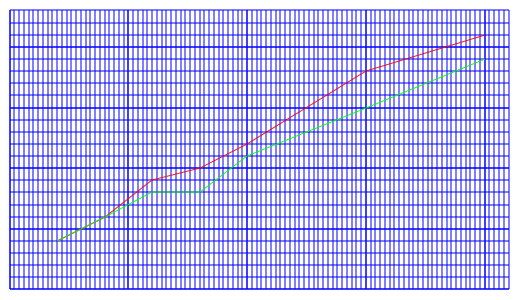

In [9]:
// Figure : couleurs greedy (rouge) vs DSATUR (vert) en fonction de n.
// (Pas de caption texte : la feature ttf de plotters n'est pas activee.)
use plotters::prelude::*;

let serie_greedy: Vec<(i32, i32)> = bm.iter().map(|&(n, cg, _)| (n as i32, cg as i32)).collect();
let serie_dsatur: Vec<(i32, i32)> = bm.iter().map(|&(n, _, cd)| (n as i32, cd as i32)).collect();
let ymax = 2 + bm.iter().map(|&(_, cg, _)| cg).max().unwrap_or(10) as i32;

let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (520, 300)).into_drawing_area();
    let mut chart = ChartBuilder::on(&root)
        .margin(10)
        .build_cartesian_2d(0i32..210i32, 0i32..ymax)?;
    chart.configure_mesh().bold_line_style(BLUE).light_line_style(BLUE).draw()?;
    chart.draw_series(LineSeries::new(serie_greedy.iter().copied(), RED.mix(0.9)))?;
    chart.draw_series(LineSeries::new(serie_dsatur.iter().copied(), GREEN.mix(0.9)))?;
    root.present()?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

### Lecture de la figure

La figure trace le **nombre de couleurs** en fonction de n pour les deux heuristiques (greedy par degré décroissant en rouge, DSATUR en vert). Deux choses à regarder :

- **l'écart vertical entre les deux courbes** : c'est le gain de qualité observé pour DSATUR sur ces instances ;
- **la croissance des deux courbes** : ces quelques instances illustrent l'augmentation du nombre de couleurs sans établir une loi asymptotique.

### Interprétation : le compromis

Trois constats, dans l'ordre d'importance :

1. **DSATUR gagne en couleurs à presque tous les n**, de 1 à 3 couleurs d'avance sur ce benchmark (greedy − DSATUR : 0 à n = 20 et 40, puis 1, 2, 1, 3, 2) — le même écart qualitatif que mesure le jumeau Python sur ses propres instances. Le coût de ce gain reste modeste : DSATUR est plus lent que greedy (de ~2× à n = 20-40 jusqu'à ~8-10× aux grandes tailles, avec un pic à ~75× sur l'instance n = 80), mais les deux heuristiques restent dans la gamme des **microsecondes à quelques millisecondes** — invisible à l'échelle humaine.
2. **La preuve exacte tient à n = 20 et n = 40, pas au-delà.** Le backtracking prouve χ = 4 en ~11 µs à n = 20, puis χ = 6 en ~3,8 ms à n = 40 ; au-delà (n ≥ 60), on ne lance plus la preuve : son coût explose. Le jumeau Python, avec la propagation industrielle de CP-SAT, repousse le mur à n = 60-80 — mais le mur est le même : exponentiel reste exponentiel.
3. **Les deux courbes montent ensemble**, grosso modo comme n / log n : la densité 0,3 fixe la structure, la taille fixe la difficulté. Aucune heuristique ne casse cette pente — elles la descendent d'un petit offset.

C'est la leçon d'ingénierie du jumeau Python, inchangée en Rust : **heuristique pour la solution, énumération bornée pour la preuve — et savoir laquelle des deux réponses on est en train de lire**.

## 4. Exercices

### Exercice 1 : l'Amérique du Sud

Construisez le graphe des 10 pays d'Amérique du Sud (Colombie, Venezuela, Brésil, Équateur, Pérou, Bolivie, Paraguay, Argentine, Chili, Uruguay — la Guyane n'est pas un pays) et coloriez-le avec vos trois outils : greedy (ordre par défaut), DSATUR, et preuve exacte.

**Objectif** : retrouver le verdict du jumeau Python — 10 sommets, 19 arêtes, et χ = 4 (une clique de 4 pays, p. ex. Brésil–Pérou–Bolivie–Paraguay, interdit de descendre en dessous).

**Indice** : réutilisez la structure de la cellule du greedy — dictionnaire d'adjacences des deux sens, dédoublonnage par `contains_edge`, puis `greedy` / `dsatur` / `enumere` sur l'adjacence indexée. La preuve exacte : k = 3 doit rendre 0 solution en exploration complète.

In [10]:
// EXERCICE 1 -- Amerique du Sud.
fn adjacence_amerique_du_sud() -> Vec<(&'static str, Vec<&'static str>)> {
    // TODO etudiant : les 10 pays et leurs frontieres terrestres, dans les deux sens.
    // (Colombie, Venezuela, Bresil, Equateur, Perou, Bolivie, Paraguay, Argentine, Chili, Uruguay)
    Vec::new()
}

let pays = adjacence_amerique_du_sud();
println!("Exercice a completer : {} pays declares (attendu : 10)", pays.len());
// Etapes conseillees :
//   1. construire le graphe petgraph et verifier : 10 sommets, 19 aretes ;
//   2. extraire l'adjacence indexee, lancer greedy puis DSATUR ;
//   3. enumere(adj, 3, gros_budget, usize::MAX) -> attendu 0 solution complete,
//      enumere(adj, 4, gros_budget, 1) -> attendu 1 : chi = 4.

Exercice a completer : 0 pays declares (attendu : 10)


### Exercice 2 : solides platoniciens

Deux graphes réguliers emblématiques : le **cube** (8 sommets, 12 arêtes, degré 3) et l'**octaèdre** (6 sommets, 12 arêtes, degré 4).

**Objectif** : pour chacun, calculer greedy (degré décroissant), DSATUR et χ exact — et expliquer pourquoi le cube tombe à 2 alors que l'octaèdre tombe à 3.

**Indice** : un graphe est **biparti** (χ = 2) si et seulement si 2 couleurs suffisent — le cube est le graphe bipartite K₄,₄ moins un couplage parfait. L'octaèdre contient des triangles (chaque face). Votre preuve : `enumere(adj, 2, ...)` qui rend 0 solution complète pour l'octaèdre, une solution pour le cube.

In [11]:
// EXERCICE 2 -- Cube et octaedre.
fn adjacence_solide(nom: &str) -> Vec<Vec<usize>> {
    // TODO etudiant : "cube" -> 8 sommets, 12 aretes (chaque sommet voit 3 voisins) ;
    // "octaedre" -> 6 sommets, 12 aretes (chaque sommet voit 4 voisins).
    // Un encodage possible pour le cube : sommets (x, y, z) de {0,1}^3,
    // deux sommets adjacents s'ils different d'exactement une coordonnee.
    let _ = nom;
    Vec::new()
}

let cube = adjacence_solide("cube");
println!("Exercice a completer : {} sommets pour le cube (attendu : 8)", cube.len());
// Puis : greedy, dsatur, enumere sur les deux solides ;
// attendu : cube chi = 2 (biparti), octaedre chi = 3 (faces triangulaires).

Exercice a completer : 0 sommets pour le cube (attendu : 8)


### Exercice 3 : coloration d'arêtes via le graphe des arêtes

Jusqu'ici on a colorié des **sommets**. La **coloration d'arêtes** (χ′) assigne une couleur à chaque arête telle que deux arêtes adjacentes (partageant une extrémité) diffèrent — le problème d'ordonnancement de matchs. L'astuce classique : construire le **graphe des arêtes** (line graph) L(G) — un sommet de L(G) par arête de G, deux sommets de L(G) adjacents si les arêtes correspondantes se touchent — puis colorier L(G) comme un graphe de sommets ordinaire.

**Objectif** : implémenter `graphe_des_aretes`, puis comparer χ′ du cube, de K₄ et du graphe de Petersen avec la borne de **Vizing** (Δ ≤ χ′ ≤ Δ + 1).

**Indice** : deux arêtes (a, b) et (c, d) de G sont adjacentes ssi elles partagent une extrémité. Les arêtes de G se numéroent par paires u < v ; attention, un `Graph` petgraph autorise les arêtes parallèles, mais vos adjacences indexées n'en ont pas. Verdicts attendus (jumeau Python) : cube χ′ = 3 (Kőnig : biparti → χ′ = Δ = 3), K₄ χ′ = 3 (Δ + 1), Petersen χ′ = 4 (Δ = 3, mais χ′ = Δ + 1 : c'est un snark).

In [12]:
// EXERCICE 3 -- Coloration d'aretes via le line graph.
fn graphe_des_aretes(adj: &[Vec<usize>]) -> Vec<Vec<usize>> {
    // TODO etudiant : un sommet par arete (u, v) de u < v ;
    // deux aretes voisines quand elles partagent une extremite.
    let _ = adj;
    Vec::new()
}

// Petit exemple de controle : le triangle (3 aretes toutes voisines).
let triangle: Vec<Vec<usize>> = vec![vec![1, 2], vec![0, 2], vec![0, 1]];
let la = graphe_des_aretes(&triangle);
println!("Exercice a completer : {} sommets dans le graphe des aretes du triangle (attendu : 3)", la.len());
// Puis : chi'(cube) = 3, chi'(K4) = 3, chi'(Petersen) = 4 -- via dsatur sur L(G).

Exercice a completer : 0 sommets dans le graphe des aretes du triangle (attendu : 3)


## À retenir

- **petgraph** est l'organe à graphes de l'écosystème Rust (`Graph<&str, (), Undirected>`, `neighbors`, `contains_edge`) — mais il n'a ni `is_planar` ni solveur : la coloration, c'est vous qui l'écrivez.
- Le **gluton (greedy)** est en O(V + E) et sa qualité dépend de l'**ordre** : 4 couleurs sur certains ordres, 5 sur d'autres, pour le même graphe. Ordre par degré décroissant (Welsh-Powell) = le meilleur réflexe par défaut.
- **DSATUR** remplace l'ordre figé par un choix dynamique du sommet le plus **saturé** : déterministe, O(V²), et il a refermé le carnet des départements en 4 couleurs.
- **Prouver** χ demande l'échec complet de l'énumération à k − 1 couleurs : backtracking + MRV + forward checking + brisure de symétrie. À 18 sommets, millisecondes ; à 40, le budget explose — c'est un problème NP-complet, aucun langage n'y échappe.
- **L'aléatoire Rust est un type** : `StdRng::seed_from_u64` par instance, reproductible graine par graine — mais un générateur différent de celui de Python donne des instances différentes : on compare des ordres de grandeur, pas des comptes exacts.

## Vérifiez votre compréhension

**1. Pourquoi Welsh-Powell (degré décroissant) fait-il mieux que le degré croissant sur les départements ?**

<details><summary>Réponse</summary>

Les sommets à fort degré ont le plus de contraintes : coloriés tôt, ils choisissent parmi des couleurs encore libres ; coloriés tard, leur voisinage a déjà consommé des couleurs toutes différentes et ils en déclenchent une neuvième. Traiter d'abord les plus contraints (Seine-et-Marne, degré 9) laisse les petits degrés se replier dans les interstices — la même intuition que DSATUR, mais figée dans un ordre de départ.
</details>

**2. Que prouve exactement l'échec de l'énumération à k = 3 sur les départements ?**

<details><summary>Réponse</summary>

Que **aucune** 3-coloration propre n'existe — à condition que l'exploration soit **complète** (aucune coupure de budget). Combinée à une 4-coloration exhibée, cela prouve χ(G) = 4 : borne inférieure + borne supérieure coïncident. Une exploration coupée par le budget ne prouve rien : elle n'a vu qu'une partie de l'arbre.
</details>

**3. Le compteur de 40 3-colorations sur le graphe de Petersen, à quoi sert-il ?**

<details><summary>Réponse</summary>

C'est un **témoin de correction** du solveur. Le Petersen admet exactement 120 3-colorations propres ; la brisure de symétrie (sommet 0 figé en couleur 0) en laisse exactement 120 / 3! × 1 = 40... plus précisément 120 / 3 = 40, car fixer la couleur d'un sommet sélectionne un tiers des colorations (une par permutation cyclique des couleurs). Une implémentation erronée du forward checking ou de la restauration de domaine dévierait de cette valeur.
</details>

**4. Pourquoi ce carnet n'utilise-t-il pas la crate `cp_sat` comme le jumeau Python utilise OR-Tools ?**

<details><summary>Réponse</summary>

La crate `cp_sat` lie le moteur C++ OR-Tools, qui ne publie aucun binaire pour Windows : il faudrait une installation Linux sous WSL avec `ORTOOLS_PREFIX` — un prérequis système mesuré hors du périmètre d'un carnet portable (détail dans `docs/reference/rust-porting-spec.md`). Ce jumeau assume l'implémentation brute : un backtracking exact borné, suffisant à cette taille de graphe, et pédagogiquement plus transparent qu'un solveur boîte noire.
</details>

## Pour aller plus loin

- [App-02-GraphColoring-Python.ipynb](App-02-GraphColoring-Python.ipynb) : le jumeau complet — exemples guidés supplémentaires (États-Unis, Europe de l'Ouest, icosaèdre, dodécaèdre), trace DSATUR manuelle, et la colonne CP-SAT du benchmark.
- [App-02-GraphColoring-CSharp.ipynb](App-02-GraphColoring-CSharp.ipynb) : le troisième jumeau, en .NET avec Google.OrTools.
- [App-03-NurseScheduling-Python.ipynb](App-03-NurseScheduling-Python.ipynb) : la coloration de graphes devient un vrai problème d'horaires.
- Brélaz & de Werra : la famille des heuristiques de saturation (DSATUR, then RLF de Leighton) — un bon sujet de mini-projet : implémenter RLF en Rust et le comparer à DSATUR sur G(n, 0,3).
- [Carte de l'écosystème Rust](../../../docs/reference/rust-ecosystem-map.md) du dépôt : où `z3` est le point le plus fort de l'écosystème natif, pour les envies de solveur.